# Plotting, saving, loading

A result is worth little until it can be seen and kept. This tutorial goes through the tools Spatialize
gives for both, colour palettes suited to scientific maps, themes that set the look of every figure at
once, plotting functions for maps on grids and at scattered locations, for amounts and for categories,
the quick plots of each result, and the functions that save a result to disk and load it back with the
settings it was computed with.

## Learning goals

- Which colour palettes Spatialize bundles, and how to use them.
- How a theme sets the look of a group of figures, inside a `with` block.
- Which function draws which kind of map, on a grid or at scattered locations, amounts or categories.
- How to save a result, with its simulations, and load it back unchanged.

*How to show a result, and keep it?*

## The idea

The palettes include the scientific colour maps of Fabio Crameri, designed so that equal steps in the
value look like equal steps in colour and remain readable in grey and to readers with a colour vision
deficiency. `PlotStyle` gathers a theme, a palette for values and one for uncertainty, applied to every
figure drawn inside its `with` block and undone at the end. The plotting functions take the arrays a
result returns, so the same call draws an estimate, a precision or a simulated field. A saved result is
a folder holding the estimate, the members, the locations and a description, enough to rebuild the
result object.

## Step by step

### Palettes

`get_available_palettes()` lists the palettes, `show_palettes()` draws them, and
`get_palette_colormap(name)` turns one into a Matplotlib colour map.

45 palettes, among them alges, alges_muted, precision, precision_dark, precision_muted, crest_r, acton, bam


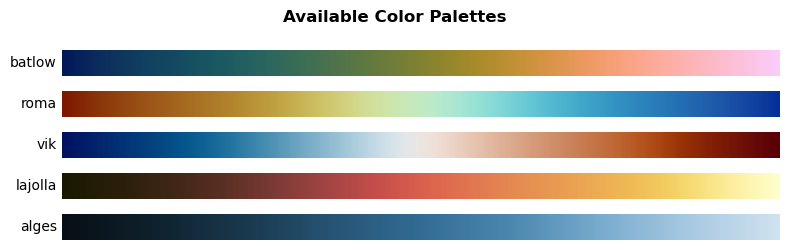

In [1]:
import os
import tempfile

import numpy as np
import matplotlib.pyplot as plt

import spatialize
from spatialize.data import load_simulated_anisotropic_data, save_result, load_result
from spatialize.empirical import FittedModelFactory
from spatialize.evaluation import SyntheticScenario
from spatialize.gs.esi import esi_griddata, esi_nongriddata
from spatialize.gs.ess import ess_sample
from spatialize.logging import singleton_null_callback as quiet
from spatialize.viz import (PlotStyle, get_available_palettes, show_palettes, get_palette_colormap, plot_colormap_data,
                            plot_nongriddata, plot_scatter, plot_histogram, plot_categorical_scatter, plot_categorical_colormap)

spatialize.session.set(empty_cells="coarsen", progress=False)

palettes = get_available_palettes()
print(f"{len(palettes)} palettes, among them {', '.join(list(palettes)[:8])}")
show_palettes(["batlow", "roma", "vik", "lajolla", "alges"])
plt.show()

### A result to draw

An ensemble estimate of the anisotropic field used across this gallery, on its 200 × 200 grid, gives the
maps for the rest of the tutorial.

In [2]:
(samples, _), _, _, grid = load_simulated_anisotropic_data()
points, values = samples[["x", "y"]].values, samples["sim1"].values
xi = np.mgrid[0:200, 0:200].astype(float)
result = esi_griddata(points, values, xi, local_interpolator="sharpidw", n_partitions=100, alpha=0.95, seed=0)
estimate, precision = result.estimation(), result.precision()
print(estimate.shape)

(200, 200)


### Themes

`PlotStyle(theme=...)` sets the background, the grid, the fonts and the default palettes. Inside its
`with` block every figure follows it, and the previous settings return at the end.

['darkgrid', 'whitegrid', 'dark', 'white', 'alges', 'alges_muted', 'minimal', 'publication']


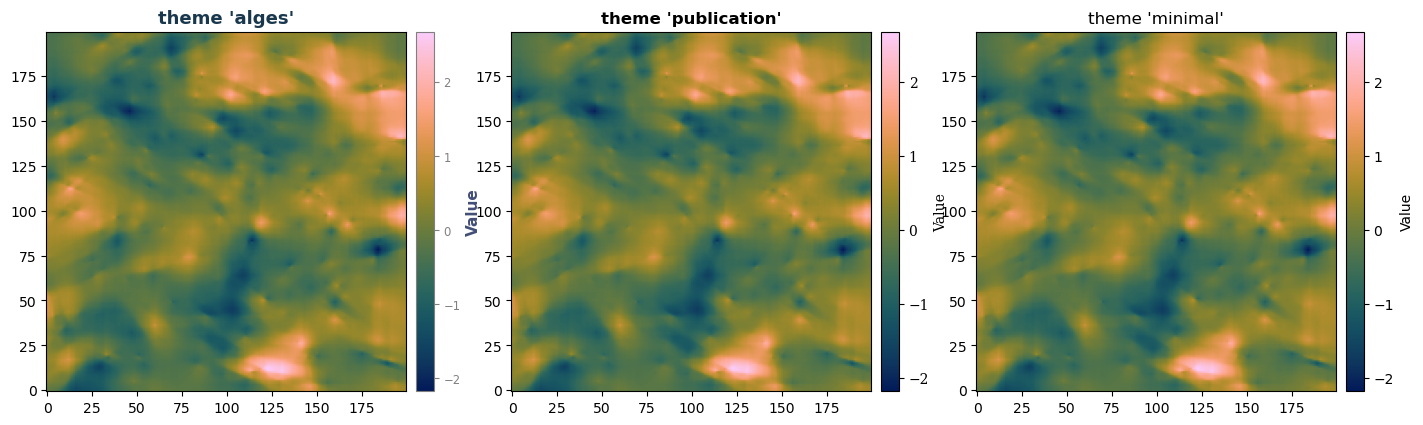

In [3]:
print(PlotStyle().get_available_themes())
fig, axes = plt.subplots(1, 3, figsize=(17, 4.8))
for ax, theme in zip(axes, ("alges", "publication", "minimal")):
    with PlotStyle(theme=theme, cmap="batlow") as style:
        plot_colormap_data(estimate, ax=ax, griddata=True, cmap=style.cmap, title=f"theme {theme!r}")
plt.show()

### Maps on a grid, maps at scattered locations

`plot_colormap_data` draws values on a full grid. `plot_nongriddata` draws values on the nodes of a
lattice that cover an irregular area, a lake or a basin, leaving the rest of its rectangle empty.
`plot_scatter` draws the data themselves, and `plot_histogram` the distribution of any values.

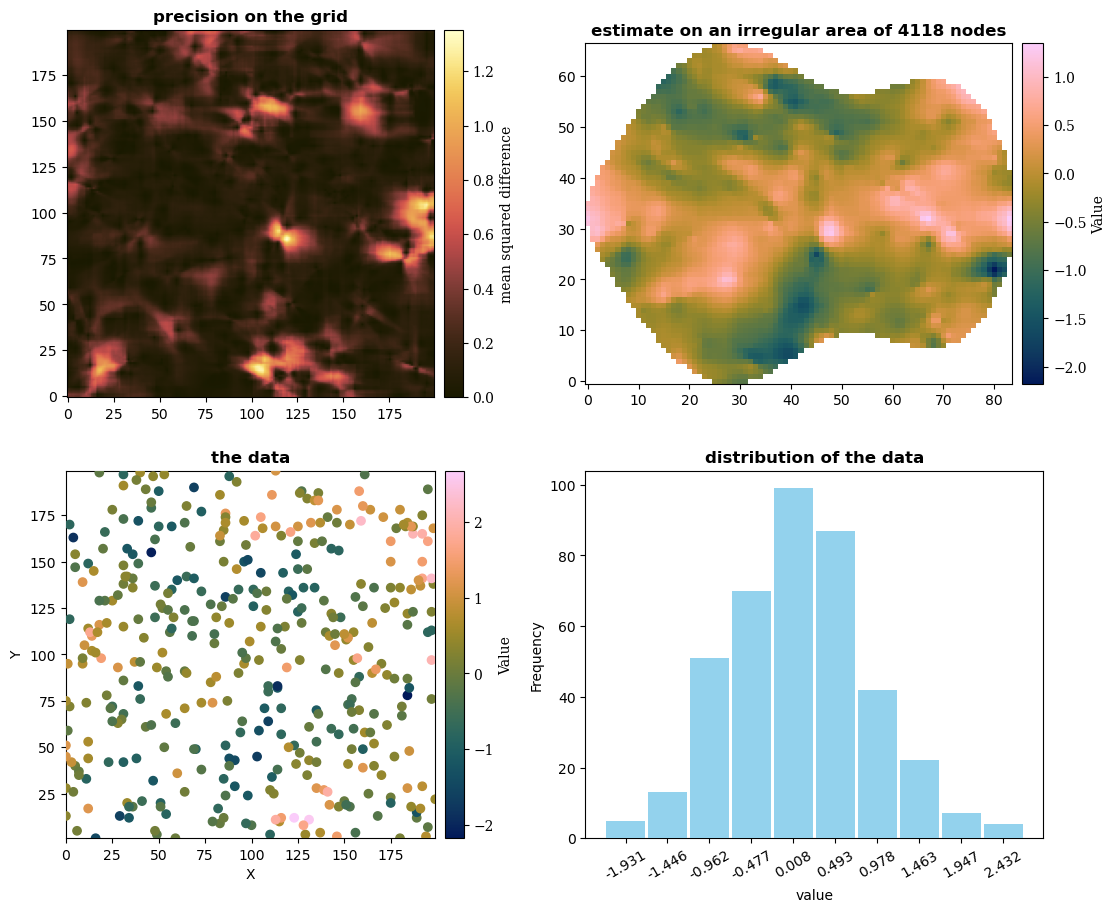

In [4]:
lattice = np.stack(np.meshgrid(np.arange(0.0, 200.0, 2.0), np.arange(0.0, 200.0, 2.0), indexing="ij"), -1).reshape(-1, 2)
x, y = lattice[:, 0] - 100, lattice[:, 1] - 100
area = lattice[(x / 90) ** 2 + (y / 60) ** 2 + 0.3 * np.sin(x / 15) < 1]      # an irregular region of the grid
area_estimate = esi_nongriddata(points, values, area, local_interpolator="sharpidw", n_partitions=100,
                                alpha=0.95, seed=0).estimation()
fig, axes = plt.subplots(2, 2, figsize=(13, 10.5))
with PlotStyle(theme="publication", cmap="batlow", precision_cmap="lajolla") as style:
    plot_colormap_data(precision, ax=axes[0, 0], griddata=True, cmap=style.precision_cmap, title="precision on the grid",
                       cbar_label="mean squared difference")
    plot_nongriddata(area_estimate, area, ax=axes[0, 1], cmap=style.cmap)
    axes[0, 1].set_title(f"estimate on an irregular area of {len(area)} nodes")
    plot_scatter(points, values, ax=axes[1, 0], fig=fig, cmap=style.cmap, title="the data", theme="publication")
    plot_histogram(values, ax=axes[1, 1])
    axes[1, 1].set_title("distribution of the data"); axes[1, 1].set_xlabel("value")
plt.show()

The precision lights up where the partitions disagree, the irregular area keeps its outline with the
rest of its rectangle empty, and the histogram shows the distribution of the data the maps come from.
The axes of `plot_nongriddata` count the nodes of the lattice, so a coordinate reads as a node number.

### Categories

For a categorical variable, `plot_categorical_scatter` and `plot_categorical_colormap` give each
category its own colour and a legend, in a given order when the categories are ordered.

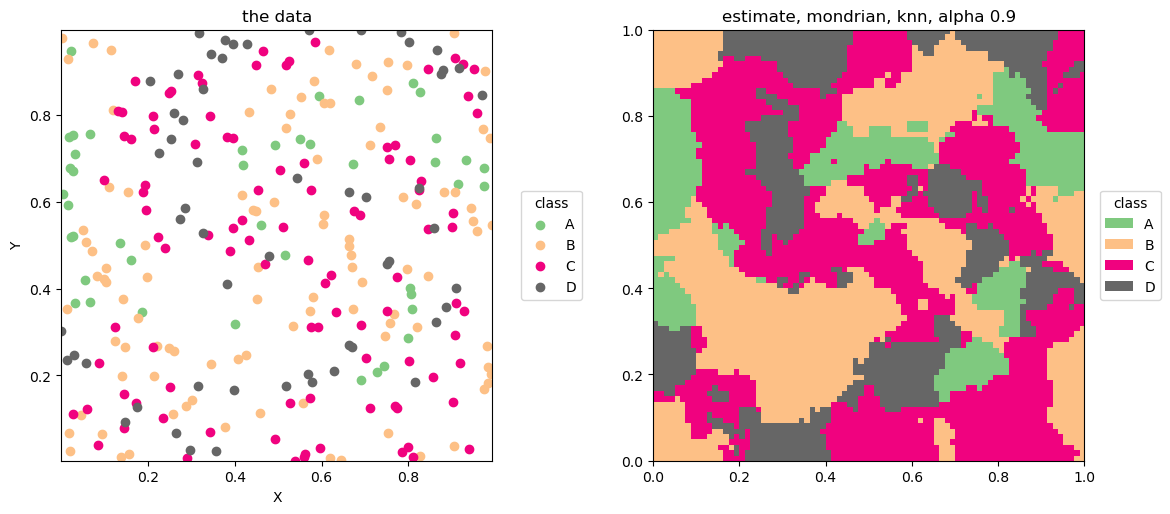

In [5]:
from spatialize.gs.cat_esi import cat_esi_nongriddata
scenario = SyntheticScenario(categorical=True, n_grid_points=80)
cat_points, cat_values, cat_xi, cat_truth = scenario.simulate_scenario(n_samples=300, seed=1)
cat_estimate = cat_esi_nongriddata(cat_points, cat_values, cat_xi, classifier="knn", n_partitions=100, alpha=0.9, seed=0).estimation()
fig, axes = plt.subplots(1, 2, figsize=(14, 5.6))
plot_categorical_scatter(cat_points, cat_values, ax=axes[0], fig=fig, title="the data", legend_title="class")
plot_categorical_colormap(cat_estimate, xi_locations=cat_xi, ax=axes[1], title="estimate, mondrian, knn, alpha 0.9",
                          legend_title="class", extent=(0, 1, 0, 1))
plt.show()

### Quick plots of a result

Every estimation result has `quick_plot()`, the estimate beside its precision, and every simulation
result has its own, a grid of simulated fields.

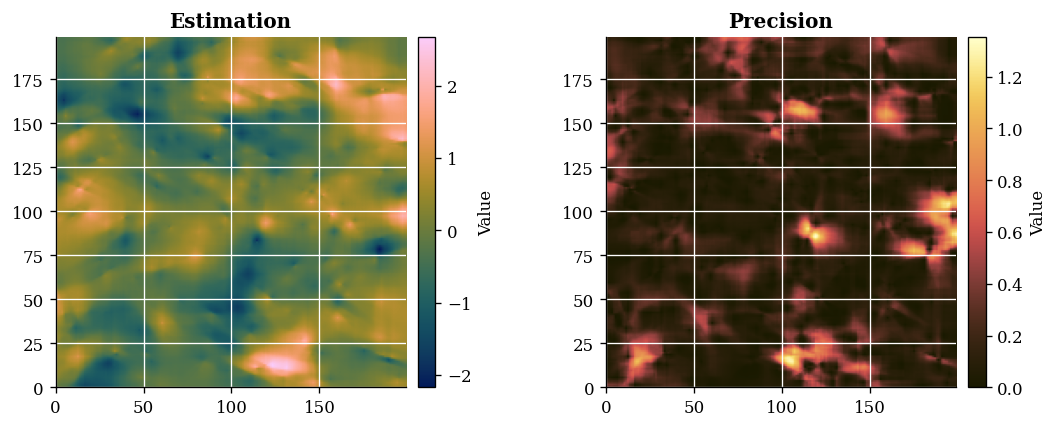

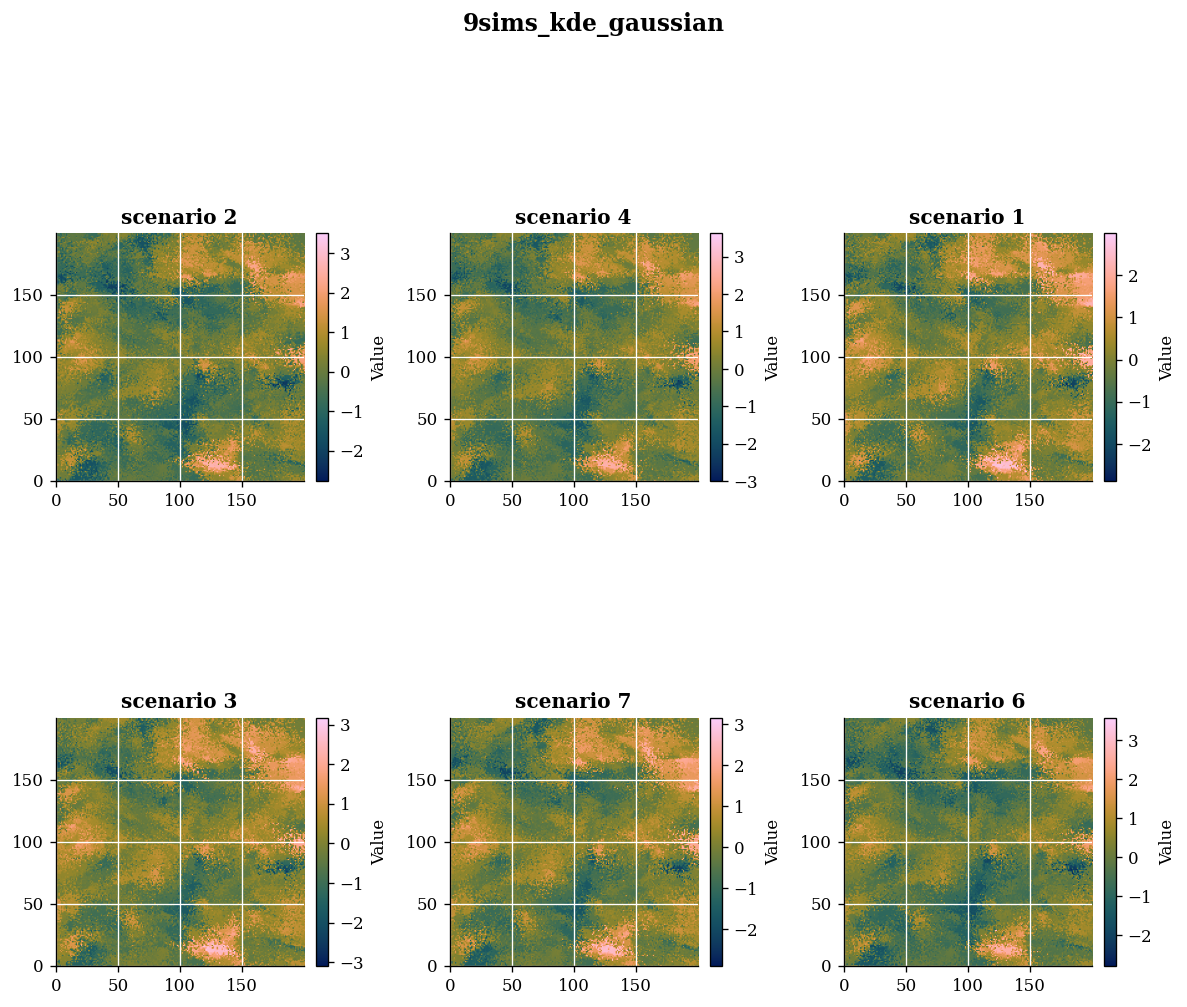

In [6]:
result.quick_plot(theme="publication", estimation_cmap="batlow", precision_cmap="lajolla")
plt.show()
simulation = ess_sample(result, n_sims=9, fitted_model_factory=FittedModelFactory(seed=0), callback=quiet)
simulation.quick_plot(n_imgs=6, n_cols=3, theme="publication", cmap="batlow")
plt.show()

### Saving, loading

`save_result(folder, result)` writes a result to a folder, the estimate, the members, the locations and
a file of metadata with the settings of the run. Saving a simulation into the same folder adds its
fields. `load_result(folder)` rebuilds the result, the estimation alone with `just_esi_result=True`, or
the list of simulations otherwise.

In [7]:
folder = os.path.join(tempfile.mkdtemp(), "anisotropic_sharpidw")
save_result(folder, result)
save_result(folder, simulation)
print(sorted(os.listdir(folder)))

loaded = load_result(folder, just_esi_result=True)
simulations = load_result(folder)
largest = lambda a, b: np.nanmax(np.abs(np.asarray(a, dtype=float) - np.asarray(b, dtype=float)))
print(f"largest difference, estimate {largest(loaded.estimation(), result.estimation()):.1e}, "
      f"members {largest(loaded.esi_samples(), result.esi_samples()):.1e}")
print(f"simulations loaded: {len(simulations)}, largest difference "
      f"{largest(simulations[0].scenarios, simulation.scenarios):.1e}")
print("settings kept:", {k: loaded.effective_config[k] for k in list(loaded.effective_config)[:5]})

['9sims_kde_gaussian.csv', 'esi_samples.csv', 'estimation.csv', 'locations.csv', 'metadata.json', 'points.csv', 'values.csv']
largest difference, estimate 1.2e-07, members 1.2e-07
simulations loaded: 1, largest difference 4.4e-16
settings kept: {'domain': None, 'parallel': True, 'num_threads': None, 'empty_cells': 'coarsen', 'mark_source': 'local'}


The folder holds the estimate, the locations, the members, the data and the simulated fields, with
the metadata that names them. The loaded result matches the saved one to the precision of single-precision
numbers, the estimate and the members having been computed in single precision and written as text. The
settings of the run come back with it, in `effective_config`, so a loaded result says how it was
computed.

## Pitfalls

- **A rainbow palette.** Its bright bands invent edges the data do not have. Prefer the scientific
  palettes, `batlow` for values, a diverging one such as `vik` for values around zero.
- **Settings changed outside a `with` block.** A `PlotStyle` used without `with` keeps its settings
  until `reset_to_original()` is called.
- **A grid drawn transposed.** Maps from `np.mgrid` are indexed `[x, y]`. The plotting functions handle
  that order, while a plain `plt.imshow` needs the transpose and `origin="lower"`.
- **A folder reused for another result.** Saving into a folder that holds another result mixes their
  files. Give each result its own folder.

## Try it yourself

1. Draw the precision with a diverging palette and see why a sequential one suits it better.
2. Save a categorical result and load it back.
3. Define a palette from your own list of colours, `PlotStyle(cmap=["#00204c", "#7c7b78", "#ffe945"])`.

## Next

- *A first ensemble map*, for the estimate and its precision.
- *Ensemble spatial simulation*, for the simulated fields.
- *Evaluating an interpolator*, for the metrics.
- The documentation's [Plotting](https://spatialize.readthedocs.io/en/latest/reference/viz.html) and
  [Saving results](https://spatialize.readthedocs.io/en/latest/reference/data.html) (reference).